<a href="https://colab.research.google.com/github/Opsimtech/CFD-ML-model/blob/main/Flettner_Rotor_chatGPT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Flettner-rotor PINN — Colab notebook

**Case taken from the uploaded manuscript and data:** steady 2D incompressible RANS, SST-like $k$–$\omega$ closure, $Re=3.6\times10^5$, spin ratio $\alpha=2$, cylinder radius $r/D=0.5$, far-field radius $25D$, and the 30 Bordogna $C_p(\theta)$ observations extracted from `CP data.xlsx`.

The network has six hidden layers of 128 `tanh` units. Lift and drag are **not** used in the training loss; they are calculated after training by integrating pressure and effective viscous stress. Manuscript reference values for post-training comparison are $C_L=5.917$ and $C_D=1.745$.

**Important scientific caution:** this is a research prototype, not a guaranteed reproduction of the authors' original implementation. High-Reynolds-number SST PINNs are stiff and may fail to converge even when the code runs. The notebook includes a quick/debug mode by default. Switch to `RUN_MODE = "manuscript"` only after a successful quick run and monitor all residuals. The near-wall SST $\omega$ condition is numerically regularized by a configurable cap; report that choice if using results in a publication. Do not claim validation based only on low training loss.

In [1]:
import importlib
import sympy

sympy.core = importlib.import_module("sympy.core")

import torch
print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cu130


In [2]:
# Colab setup
import os, math, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 1. Case configuration and uploaded experimental data

The pressure observations below are the 30 rows for `k = 2, Re = 3.6×10⁵` extracted from the uploaded `CP data.xlsx`. The force coefficients are reference-only and are **not** used in optimization.

The manuscript's full training configuration is 6,000 epochs and 20,000 interior collocation points per epoch. For a practical Colab first run, the default debug mode uses fewer points/epochs; change `RUN_MODE` after verifying that the notebook executes and losses remain finite.

Re=3.6e+05, alpha=2.0, omega_inf*=0.366
Raw dimensionless wall omega=6.173e+05; regularized target=1.000e+04
Mode=manuscript: epochs=6000, interior points/epoch=2000


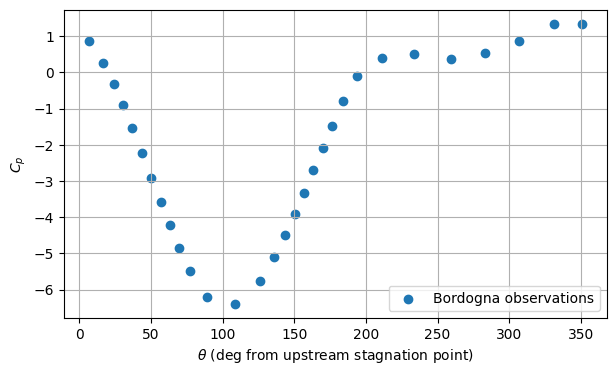

In [3]:
# Physical / dimensionless case (D and U_inf are the length and velocity scales)
RE = 3.6e5
ALPHA = 2.0                 # alpha = Omega*D/(2*U_inf) = wall speed / U_inf
R_IN = 0.5                  # cylinder radius in D units
R_OUT = 25.0                # outer boundary radius in D units
NU = 1.0 / RE               # dimensionless kinematic viscosity

# Reference measurements from manuscript (validation only; never trained on)
CL_EXP = 5.917
CD_EXP = 1.745

# Manuscript settings vs resource-friendly debug settings
RUN_MODE = "manuscript"          # choose "quick" or "manuscript"
if RUN_MODE == "manuscript":
    EPOCHS = 6000
    N_COLLOCATION = 2000
    N_BOUNDARY = 1024
    N_WALL = 512
else:
    EPOCHS = 300
    N_COLLOCATION = 1024
    N_BOUNDARY = 256
    N_WALL = 128

WIDTH = 128
DEPTH = 6
LR_INITIAL = 1e-4
LR_AFTER_STEP = 3e-5
LR_STEP_EPOCH = 3000
GRAD_CLIP = 5.0
LOG_EVERY = 25 if RUN_MODE == "quick" else 100

# SST constants (standard Menter SST constants)
BETA_STAR = 0.09
A1 = 0.31
BETA1, BETA2 = 0.075, 0.0828
GAMMA1, GAMMA2 = 5.0/9.0, 0.44
SIGMA_K1, SIGMA_K2 = 0.85, 1.0
SIGMA_W1, SIGMA_W2 = 0.5, 0.856

# Free-stream turbulence from manuscript: Tu=1%, k_inf/U_inf^2 = 1.5 Tu^2.
K_INF = 1.5e-4
# Manuscript gives dimensional omega_inf=2 s^-1; nondimensional omega*=omega*D/U_inf.
U_INF_PHYS = 5.465
D_PHYS = 1.0
OMEGA_INF = 2.0 * D_PHYS / U_INF_PHYS

# Smooth-wall SST omega estimate based on manuscript's first-cell-height formula.
# The raw asymptotic value is extremely stiff in a PINN; cap it for numerical regularization.
Y1_D = 6e-5
OMEGA_WALL_RAW = 60.0 * NU / (BETA1 * Y1_D**2)
OMEGA_WALL_CAP = 1.0e4
OMEGA_WALL = min(OMEGA_WALL_RAW, OMEGA_WALL_CAP)
K_WALL = 1e-8
print(f"Re={RE:.3g}, alpha={ALPHA}, omega_inf*={OMEGA_INF:.4g}")
print(f"Raw dimensionless wall omega={OMEGA_WALL_RAW:.3e}; regularized target={OMEGA_WALL:.3e}")
print(f"Mode={RUN_MODE}: epochs={EPOCHS}, interior points/epoch={N_COLLOCATION}")

# Cp data: angle is measured from the forward/upstream stagnation point.
THETA_DEG = np.array([
  6.45987654320987,16.2654320987654,23.8919753086419,30.429012345679,
  36.966049382716,43.503086419753,50.0401234567901,56.5771604938271,
  63.1141975308641,69.6512345679012,77.2777777777777,89.2623456790123,
  108.873456790123,126.305555555555,136.111111111111,143.737654320988,
  150.274691358025,156.811728395062,163.348765432098,169.885802469136,
  176.422839506173,184.049382716049,193.854938271605,211.287037037037,
  233.803497942386,259.225308641975,283.194444444444,307.163580246914,
  331.132716049383,350.743827160494
], dtype=np.float32)
CP_EXP = np.array([
  0.864911477411471,0.269574175824175,-0.309600122100125,-0.902243589743591,
  -1.53978428978429,-2.21324277574277,-2.90466015466014,-3.57811864061864,
  -4.22463878713878,-4.84871031746031,-5.49859775641025,-6.19370312227454,
  -6.39276695526695,-5.76192002442002,-5.10462454212454,-4.49402218152217,
  -3.9193376068376,-3.32669413919413,-2.70711233211233,-2.07855107855107,
  -1.46794871794871,-0.781021062271062,-0.0994810744810763,0.410388222888222,
  0.510522656355984,0.361409423909425,0.525488400488399,0.87568681318681,
  1.34833222333222,1.34518358625501
], dtype=np.float32)
assert len(THETA_DEG) == len(CP_EXP) == 30
plt.figure(figsize=(7,4)); plt.scatter(THETA_DEG, CP_EXP, label="Bordogna observations")
plt.xlabel(r"$\theta$ (deg from upstream stagnation point)"); plt.ylabel(r"$C_p$"); plt.grid(True); plt.legend(); plt.show()

## 2. Network and automatic differentiation

Coordinates are nondimensionalized by $D$, velocities by $U_\infty$, pressure by $\rho U_\infty^2$, turbulent kinetic energy by $U_\infty^2$, and specific dissipation by $U_\infty/D$. The pressure gauge is fixed by setting the mean pressure on the far-field circle to zero, so $C_p=2p$ at the wall.

In [4]:
class FlowPINN(nn.Module):
    """Outputs u, v, p, log(k), log(omega) at nondimensional (x,y)."""
    def __init__(self, width=WIDTH, depth=DEPTH):
        super().__init__()
        layers = []
        in_dim = 2
        for _ in range(depth):
            layers += [nn.Linear(in_dim, width), nn.Tanh()]
            in_dim = width
        layers += [nn.Linear(in_dim, 5)]
        self.net = nn.Sequential(*layers)
        # Start near uniform flow and freestream turbulence.
        final = self.net[-1]
        nn.init.zeros_(final.weight)
        nn.init.zeros_(final.bias)
        with torch.no_grad():
            final.bias[0] = 1.0
            final.bias[1] = 0.0
            final.bias[2] = 0.0
            final.bias[3] = float(np.log(K_INF))
            final.bias[4] = float(np.log(OMEGA_INF))

    def forward(self, xy):
        z = self.net(xy)
        u, v, p = z[:,0:1], z[:,1:2], z[:,2:3]
        # Clipping prevents exponential overflow; positivity is guaranteed.
        k = torch.exp(torch.clamp(z[:,3:4], -20.0, 5.0))
        omega = torch.exp(torch.clamp(z[:,4:5], -12.0, 16.0))
        return u, v, p, k, omega, z[:,3:4], z[:,4:5]

def grad(y, x):
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y),
                               create_graph=True, retain_graph=True)[0]

def mse(x):
    return torch.mean(x*x)

model = FlowPINN().to(DEVICE)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

Trainable parameters: 83589


## 3. SST closure and RANS residuals

The residuals below enforce continuity, both momentum equations, and the two SST transport equations. A distance-to-wall approximation $d=r-0.5$ is used in the SST blending functions because the geometry is a circular annulus. This implementation should be checked against a trusted SST solver before publication; exact SST implementation details and wall treatment can differ between solvers. Log-space turbulence wall losses are scaled by 1/10 to keep them commensurate with the velocity boundary loss.

In [5]:
def rans_sst_residuals(xy):
    xy = xy.requires_grad_(True)
    u, v, p, k, omega, logk, logomega = model(xy)
    gu, gv, gp, gk, gw = grad(u,xy), grad(v,xy), grad(p,xy), grad(k,xy), grad(omega,xy)
    ux, uy = gu[:,0:1], gu[:,1:2]
    vx, vy = gv[:,0:1], gv[:,1:2]
    px, py = gp[:,0:1], gp[:,1:2]
    kx, ky = gk[:,0:1], gk[:,1:2]
    wx, wy = gw[:,0:1], gw[:,1:2]

    rad = torch.sqrt(torch.sum(xy*xy, dim=1, keepdim=True) + 1e-12)
    d = torch.clamp(rad - R_IN, min=1e-4)
    strain = torch.sqrt(torch.clamp(2*ux**2 + 2*vy**2 + (uy+vx)**2, min=1e-12))
    grad_dot = kx*wx + ky*wy
    cd_raw = 2.0*SIGMA_W2*grad_dot/torch.clamp(omega, min=1e-10)
    cd_pos = torch.clamp(cd_raw, min=1e-10)

    # SST blending functions F1/F2.
    arg_a = torch.sqrt(torch.clamp(k, min=1e-20))/(BETA_STAR*torch.clamp(omega,min=1e-10)*d)
    arg_b = 500.0*NU/(d*d*torch.clamp(omega,min=1e-10))
    arg_c = 4.0*SIGMA_W2*k/(cd_pos*d*d)
    arg1 = torch.minimum(torch.maximum(arg_a,arg_b), torch.clamp(arg_c,min=1e-10))
    F1 = torch.tanh(torch.clamp(arg1, min=0.0)**4)
    arg2 = torch.maximum(2.0*torch.sqrt(torch.clamp(k,min=1e-20))/(BETA_STAR*torch.clamp(omega,min=1e-10)*d), arg_b)
    F2 = torch.tanh(torch.clamp(arg2,min=0.0)**2)

    beta = F1*BETA1 + (1-F1)*BETA2
    gamma = F1*GAMMA1 + (1-F1)*GAMMA2
    sigk = F1*SIGMA_K1 + (1-F1)*SIGMA_K2
    sigw = F1*SIGMA_W1 + (1-F1)*SIGMA_W2
    nut_den = torch.maximum(A1*omega, strain*F2)
    nut = A1*k/torch.clamp(nut_den,min=1e-10)
    mu_eff = NU + nut

    # Effective Reynolds stress and its divergence.
    tau_xx = 2.0*mu_eff*ux
    tau_xy = mu_eff*(uy+vx)
    tau_yy = 2.0*mu_eff*vy
    div_tau_x = grad(tau_xx,xy)[:,0:1] + grad(tau_xy,xy)[:,1:2]
    div_tau_y = grad(tau_xy,xy)[:,0:1] + grad(tau_yy,xy)[:,1:2]

    continuity = ux + vy
    mom_x = u*ux + v*uy + px - div_tau_x
    mom_y = u*vx + v*vy + py - div_tau_y

    # SST production with a limiter.
    Pk_raw = nut*strain**2
    Pk = torch.minimum(Pk_raw, 20.0*BETA_STAR*k*omega)
    diff_k = (NU + sigk*nut)
    flux_kx, flux_ky = diff_k*kx, diff_k*ky
    div_diff_k = grad(flux_kx,xy)[:,0:1] + grad(flux_ky,xy)[:,1:2]
    diff_w = (NU + sigw*nut)
    flux_wx, flux_wy = diff_w*wx, diff_w*wy
    div_diff_w = grad(flux_wx,xy)[:,0:1] + grad(flux_wy,xy)[:,1:2]
    cross_diff = 2.0*(1.0-F1)*SIGMA_W2*grad_dot/torch.clamp(omega,min=1e-10)
    k_res = u*kx + v*ky - Pk + BETA_STAR*k*omega - div_diff_k
    w_res = u*wx + v*wy - gamma*omega*Pk/torch.clamp(k,min=1e-10) + beta*omega**2 - div_diff_w - cross_diff
    return (continuity, mom_x, mom_y, k_res, w_res), (u,v,p,k,omega,nut,mu_eff,(ux,uy,vx,vy))

## 4. Collocation points and loss function

Interior points use the manuscript's log-uniform radial sampling to concentrate points near the cylinder. The pressure observations are applied only at their measured angles. $C_L$ and $C_D$ are deliberately absent from the loss function.

In [6]:
def sample_annulus(n):
    # Log-uniform radial sampling: half of points lie inside the geometric-mean radius.
    th = 2*np.pi*np.random.rand(n)
    xi = np.random.rand(n)
    rr = R_IN*(R_OUT/R_IN)**xi
    arr = np.column_stack([rr*np.cos(th), rr*np.sin(th)]).astype(np.float32)
    return torch.tensor(arr, device=DEVICE)

def circle_points(radius, n):
    th = torch.linspace(0, 2*np.pi, n+1, device=DEVICE)[:-1]
    return torch.stack([radius*torch.cos(th), radius*torch.sin(th)], dim=1)

def cp_sensor_points():
    # theta=0 is upstream, so x=-R*cos(theta), y=R*sin(theta).
    th = torch.tensor(np.deg2rad(THETA_DEG), dtype=torch.float32, device=DEVICE)
    x = -R_IN*torch.cos(th); y = R_IN*torch.sin(th)
    return torch.stack([x,y],dim=1), torch.tensor(CP_EXP[:,None], dtype=torch.float32, device=DEVICE)

cp_xy, cp_obs = cp_sensor_points()
wall_xy = circle_points(R_IN, N_WALL)
ff_xy = circle_points(R_OUT, N_BOUNDARY)

# Loss weights from the manuscript. Turbulence terms and turbulence BCs are ramped in.
W_PDE, W_TURB, W_WALL, W_FF, W_CP, W_PGAUGE = 100.0, 1.0, 300.0, 10.0, 10.0, 50.0

def loss_function(epoch, xy_int):
    (cont, mx, my, kr, wr), _ = rans_sst_residuals(xy_int)
    L_cont, L_mx, L_my = mse(cont), mse(mx), mse(my)
    L_k, L_w = mse(kr), mse(wr)

    # Wall velocity: clockwise rotation, with nondimensional angular velocity Omega*D/U = 2 alpha.
    wx, wy = wall_xy[:,0:1], wall_xy[:,1:2]
    uw_target = 2.0*ALPHA*wy
    vw_target = -2.0*ALPHA*wx
    uw, vw, _, kw, ww, logkw, logww = model(wall_xy)
    L_wall_uv = mse(uw-uw_target) + mse(vw-vw_target)
    # Log-space BC errors are scaled to avoid overwhelming the velocity BC loss.
    L_wall_turb = mse((logkw - math.log(K_WALL))/10.0) + mse((logww - math.log(OMEGA_WALL))/10.0)

    uf, vf, pf, kf, wf, logkf, logwf = model(ff_xy)
    L_ff_uv = mse(uf-1.0) + mse(vf)
    L_ff_turb = mse(logkf-math.log(K_INF)) + mse(logwf-math.log(OMEGA_INF))
    L_pressure_gauge = torch.mean(pf)**2

    _, _, pcp, _, _, _, _ = model(cp_xy)
    cp_pred = 2.0*(pcp - torch.mean(pf))
    L_cp = mse(cp_pred-cp_obs)

    # Manuscript ramp: turbulence equation/BC terms off for first 1000, ramp to full by epoch 2000.
    lam = 0.0 if epoch < 1000 else min(1.0, (epoch-1000)/1000.0)
    # In quick mode, ramp over a shorter fraction so the debug run tests all terms.
    if RUN_MODE == "quick":
        lam = min(1.0, max(0.0, (epoch-20)/80.0))
    total = W_PDE*(L_cont+L_mx+L_my) + lam*W_TURB*(L_k+L_w) \
            + W_WALL*L_wall_uv + lam*W_WALL*L_wall_turb \
            + W_FF*L_ff_uv + lam*W_FF*L_ff_turb \
            + W_CP*L_cp + W_PGAUGE*L_pressure_gauge
    parts = {"total":total, "cont":L_cont, "mom_x":L_mx, "mom_y":L_my,
             "k":L_k, "omega":L_w, "wall_uv":L_wall_uv,
             "wall_turb":L_wall_turb, "farfield_uv":L_ff_uv,
             "farfield_turb":L_ff_turb, "Cp":L_cp, "p_gauge":L_pressure_gauge,
             "turb_ramp":torch.tensor(lam,device=DEVICE)}
    return total, parts

print("Sensor points:", len(CP_EXP), "| interior points/epoch:", N_COLLOCATION)

Sensor points: 30 | interior points/epoch: 2000


In [7]:

import importlib
import sys
import sympy

try:
    core = importlib.import_module("sympy.core")
    print("Imported core module:", core)
    print("Core registered:", "sympy.core" in sys.modules)

    # Explicitly attach the submodule to the SymPy package
    sympy.core = core

    print("Has sympy.core now:", hasattr(sympy, "core"))
    print("Core attribute:", sympy.core)
except Exception as e:
    print("Core import failed:", repr(e))

print("SymPy file:", sympy.__file__)
print("SymPy version:", sympy.__version__)


Imported core module: <module 'sympy.core' from '/usr/local/lib/python3.13/dist-packages/sympy/core/__init__.py'>
Core registered: True
Has sympy.core now: True
Core attribute: <module 'sympy.core' from '/usr/local/lib/python3.13/dist-packages/sympy/core/__init__.py'>
SymPy file: /usr/local/lib/python3.13/dist-packages/sympy/__init__.py
SymPy version: 1.14.0


In [8]:

import importlib
import sympy

sympy.core = importlib.import_module("sympy.core")

# Test the code path shown in your traceback
from torch.utils._sympy.functions import MinMaxBase

print("SymPy core patch applied.")
print("PyTorch SymPy functions imported successfully.")


SymPy core patch applied.
PyTorch SymPy functions imported successfully.


## 5. Train the PINN

Start with quick mode and confirm that losses remain finite. The full manuscript configuration is expensive and should be attempted only on a GPU runtime after the smoke test. Loss histories are saved for diagnosis; convergence must be assessed from both residuals and post-processed force coefficients.

epoch     0 | loss 1.602e+03 | Cp 1.022e+01 | cont 0.00e+00 | mom=(0.00e+00,0.00e+00) | turb ramp 0.00
epoch   100 | loss 8.649e+02 | Cp 9.968e+00 | cont 5.48e-03 | mom=(1.89e-01,8.55e-02) | turb ramp 0.00
epoch   200 | loss 3.964e+02 | Cp 7.029e+00 | cont 1.00e-01 | mom=(3.26e-01,5.80e-01) | turb ramp 0.00
epoch   300 | loss 2.123e+02 | Cp 3.811e+00 | cont 1.42e-01 | mom=(2.06e-01,6.00e-01) | turb ramp 0.00
epoch   400 | loss 1.181e+02 | Cp 2.682e+00 | cont 2.39e-01 | mom=(7.92e-02,2.52e-01) | turb ramp 0.00
epoch   500 | loss 6.477e+01 | Cp 1.477e+00 | cont 1.05e-01 | mom=(4.77e-02,1.79e-01) | turb ramp 0.00
epoch   600 | loss 3.052e+01 | Cp 8.222e-01 | cont 3.22e-02 | mom=(3.96e-02,8.42e-02) | turb ramp 0.00
epoch   700 | loss 1.698e+01 | Cp 4.942e-01 | cont 1.12e-02 | mom=(3.24e-02,4.11e-02) | turb ramp 0.00
epoch   800 | loss 1.012e+01 | Cp 3.063e-01 | cont 4.75e-03 | mom=(1.96e-02,2.52e-02) | turb ramp 0.00
epoch   900 | loss 9.134e+00 | Cp 2.522e-01 | cont 4.34e-03 | mom=(2.07e-

,total,cont,mom_x,mom_y,k,omega,wall_uv,wall_turb,farfield_uv,farfield_turb,Cp,p_gauge,turb_ramp,epoch,lr
5995,100.377975,0.049827,0.017166,0.032795,3.051705e-10,5.600662,0.011644,0.257419,0.021448,0.020189,0.366336,6.041378e-08,1.0,5995,0.00003
5996,101.819664,0.044528,0.022419,0.037844,2.736188e-10,6.681690,0.011560,0.257066,0.021616,0.020166,0.365325,6.385682e-08,1.0,5996,0.00003
5997,101.880768,0.040853,0.016614,0.047174,2.941069e-10,7.171502,0.011128,0.256103,0.021744,0.020169,0.365690,6.524208e-08,1.0,5997,0.00003
5998,107.346748,0.062983,0.028949,0.049068,2.712388e-10,9.281934,0.010808,0.255473,0.021911,0.020133,0.366016,7.158823e-08,1.0,5998,0.00003
5999,104.685738,0.066603,0.023080,0.039767,2.867195e-10,7.981566,0.010507,0.255038,0.021979,0.020114,0.367453,7.830208e-08,1.0,5999,0.00003


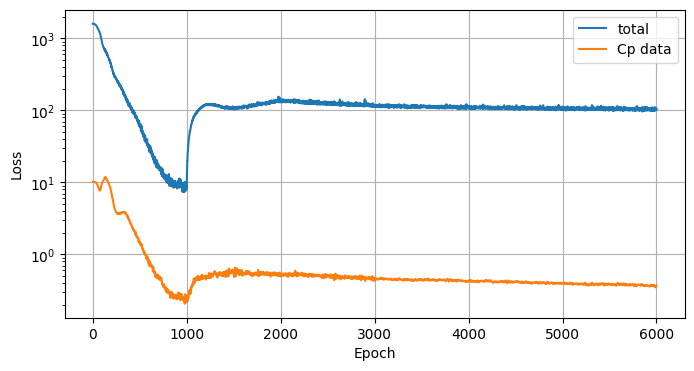

In [9]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR_INITIAL)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=LR_STEP_EPOCH, gamma=LR_AFTER_STEP/LR_INITIAL)
history = []
start = time.time()

for epoch in range(EPOCHS):
    model.train()
    xy_int = sample_annulus(N_COLLOCATION).requires_grad_(True)
    optimizer.zero_grad(set_to_none=True)
    loss, parts = loss_function(epoch, xy_int)
    if not torch.isfinite(loss):
        print(f"Non-finite loss at epoch {epoch}; stopping. Reduce LR / points or inspect SST wall treatment.")
        break
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    optimizer.step()
    # Use the manuscript's LR step only when the run reaches the step epoch.
    if epoch < LR_STEP_EPOCH:
        scheduler.step()
    rec = {k: float(v.detach().cpu()) for k,v in parts.items()}
    rec["epoch"] = epoch
    rec["lr"] = optimizer.param_groups[0]["lr"]
    history.append(rec)
    if epoch % LOG_EVERY == 0 or epoch == EPOCHS-1:
        print(f"epoch {epoch:5d} | loss {rec['total']:.3e} | Cp {rec['Cp']:.3e} | "
              f"cont {rec['cont']:.2e} | mom=({rec['mom_x']:.2e},{rec['mom_y']:.2e}) | "
              f"turb ramp {rec['turb_ramp']:.2f}")

print(f"Training wall time: {(time.time()-start)/60:.1f} min")
hist_df = pd.DataFrame(history)
if len(hist_df):
    display(hist_df.tail())
    plt.figure(figsize=(8,4)); plt.semilogy(hist_df.epoch, hist_df.total, label="total")
    plt.semilogy(hist_df.epoch, hist_df.Cp, label="Cp data")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.grid(True); plt.legend(); plt.show()

## 6. Post-process $C_p$, $C_L$, and $C_D$

The coefficients below are computed from the predicted pressure and effective stress around the cylinder. The sign convention follows the manuscript: $x$ is the freestream direction and positive lift is $+y$. If signs are reversed, inspect the angle mapping and rotation convention; do not silently take absolute values.

PINN post-processed CL = 4.0482 | manuscript reference = 5.9170
PINN post-processed CD = 1.6332 | manuscript reference = 1.7450
CL relative error (%): 31.58397348986418
CD relative error (%): 6.406634858139612


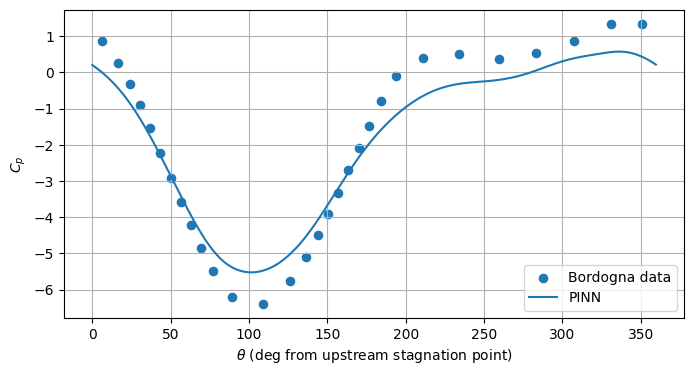

In [10]:
def evaluate_surface(n=1024):
    model.eval()
    th = torch.linspace(0, 2*np.pi, n+1, device=DEVICE)[:-1]
    # theta measured from upstream stagnation: x=-R*cos(theta), y=R*sin(theta)
    x = -R_IN*torch.cos(th); y = R_IN*torch.sin(th)
    xy = torch.stack([x,y],dim=1).requires_grad_(True)
    u,v,p,k,omega,logk,logomega = model(xy)
    gu,gv = grad(u,xy), grad(v,xy)
    ux,uy = gu[:,0:1],gu[:,1:2]
    vx,vy = gv[:,0:1],gv[:,1:2]
    # Compute SST eddy viscosity consistently with the closure used in the residual.
    rad = torch.sqrt(torch.sum(xy*xy,dim=1,keepdim=True)+1e-12)
    d = torch.clamp(rad-R_IN,min=1e-4)
    strain = torch.sqrt(torch.clamp(2*ux**2+2*vy**2+(uy+vx)**2,min=1e-12))
    # F2 is sufficient for nut; calculate its standard SST expression.
    arg_b = 500*NU/(d*d*torch.clamp(omega,min=1e-10))
    arg2 = torch.maximum(2*torch.sqrt(torch.clamp(k,min=1e-20))/(BETA_STAR*torch.clamp(omega,min=1e-10)*d),arg_b)
    F2 = torch.tanh(torch.clamp(arg2,min=0)**2)
    nut = A1*k/torch.clamp(torch.maximum(A1*omega,strain*F2),min=1e-10)
    mu = NU+nut
    tau_xx = 2*mu*ux
    tau_xy = mu*(uy+vx)
    tau_yy = 2*mu*vy
    nx,ny = x[:,None]/R_IN,y[:,None]/R_IN
    traction_x = -p*nx + tau_xx*nx + tau_xy*ny
    traction_y = -p*ny + tau_xy*nx + tau_yy*ny
    # ds = R*dtheta and coefficient = 2*integral(traction ds)
    dtheta = 2*np.pi/n
    CD = float((2*torch.sum(traction_x)*R_IN*dtheta).detach().cpu())
    CL = float((2*torch.sum(traction_y)*R_IN*dtheta).detach().cpu())
    # Explicitly subtract the predicted far-field mean pressure for Cp.
    ff_eval = circle_points(R_OUT, max(256, n//2))
    p_ref = model(ff_eval)[2].mean()
    cp = (2*(p-p_ref)).detach().cpu().numpy().ravel()
    result = pd.DataFrame({"theta_deg":th.detach().cpu().numpy()*180/np.pi,
                           "Cp_pred":cp,
                           "u_wall":u.detach().cpu().numpy().ravel(),
                           "v_wall":v.detach().cpu().numpy().ravel(),
                           "k_wall":k.detach().cpu().numpy().ravel(),
                           "omega_wall":omega.detach().cpu().numpy().ravel()})
    return result, CL, CD

surface_df, CL_PINN, CD_PINN = evaluate_surface()
print(f"PINN post-processed CL = {CL_PINN:.4f} | manuscript reference = {CL_EXP:.4f}")
print(f"PINN post-processed CD = {CD_PINN:.4f} | manuscript reference = {CD_EXP:.4f}")
print("CL relative error (%):", 100*abs(CL_PINN-CL_EXP)/abs(CL_EXP))
print("CD relative error (%):", 100*abs(CD_PINN-CD_EXP)/abs(CD_EXP))

plt.figure(figsize=(8,4))
plt.scatter(THETA_DEG, CP_EXP, label="Bordogna data", s=35)
plt.plot(surface_df.theta_deg, surface_df.Cp_pred, label="PINN", lw=1.5)
plt.xlabel(r"$\theta$ (deg from upstream stagnation point)"); plt.ylabel(r"$C_p$")
plt.grid(True); plt.legend(); plt.show()

## 7. Compare the reconstructed PINN flow field against Fluent CFD

Upload `u_p_CFD_new.csv` when prompted (or set `CFD_CSV_PATH` to its path). The file's `x-coordinate` and `y-coordinate` are already in the manuscript's nondimensional coordinates, while `x-velocity`, `y-velocity`, and `pressure` are dimensional. This cell converts velocities using `U_INF_PHYS` and pressure using `rho U_inf^2` **only if the CSV does not provide** `expr:P_scaled`; otherwise it uses that exported scaled-pressure column. It compares at the CFD coordinates and reports MAE, RMSE, and normalized RMSE. The error is meaningful only if the CSV columns use the stated nondimensionalization and the CFD/PINN cases match.

**Important:** this is a pointwise comparison on CFD nodes, not an independent validation if these same CFD data were used to tune/train the PINN.

Compared 14,387 CFD points; pressure reference: expr:P_scaled from CSV


,MAE,RMSE,NRMSE_range
u / U_inf,0.328692,0.572357,0.119387
v / U_inf,0.243472,0.453414,0.113666
p / (rho U_inf^2),0.513645,0.933769,0.117308


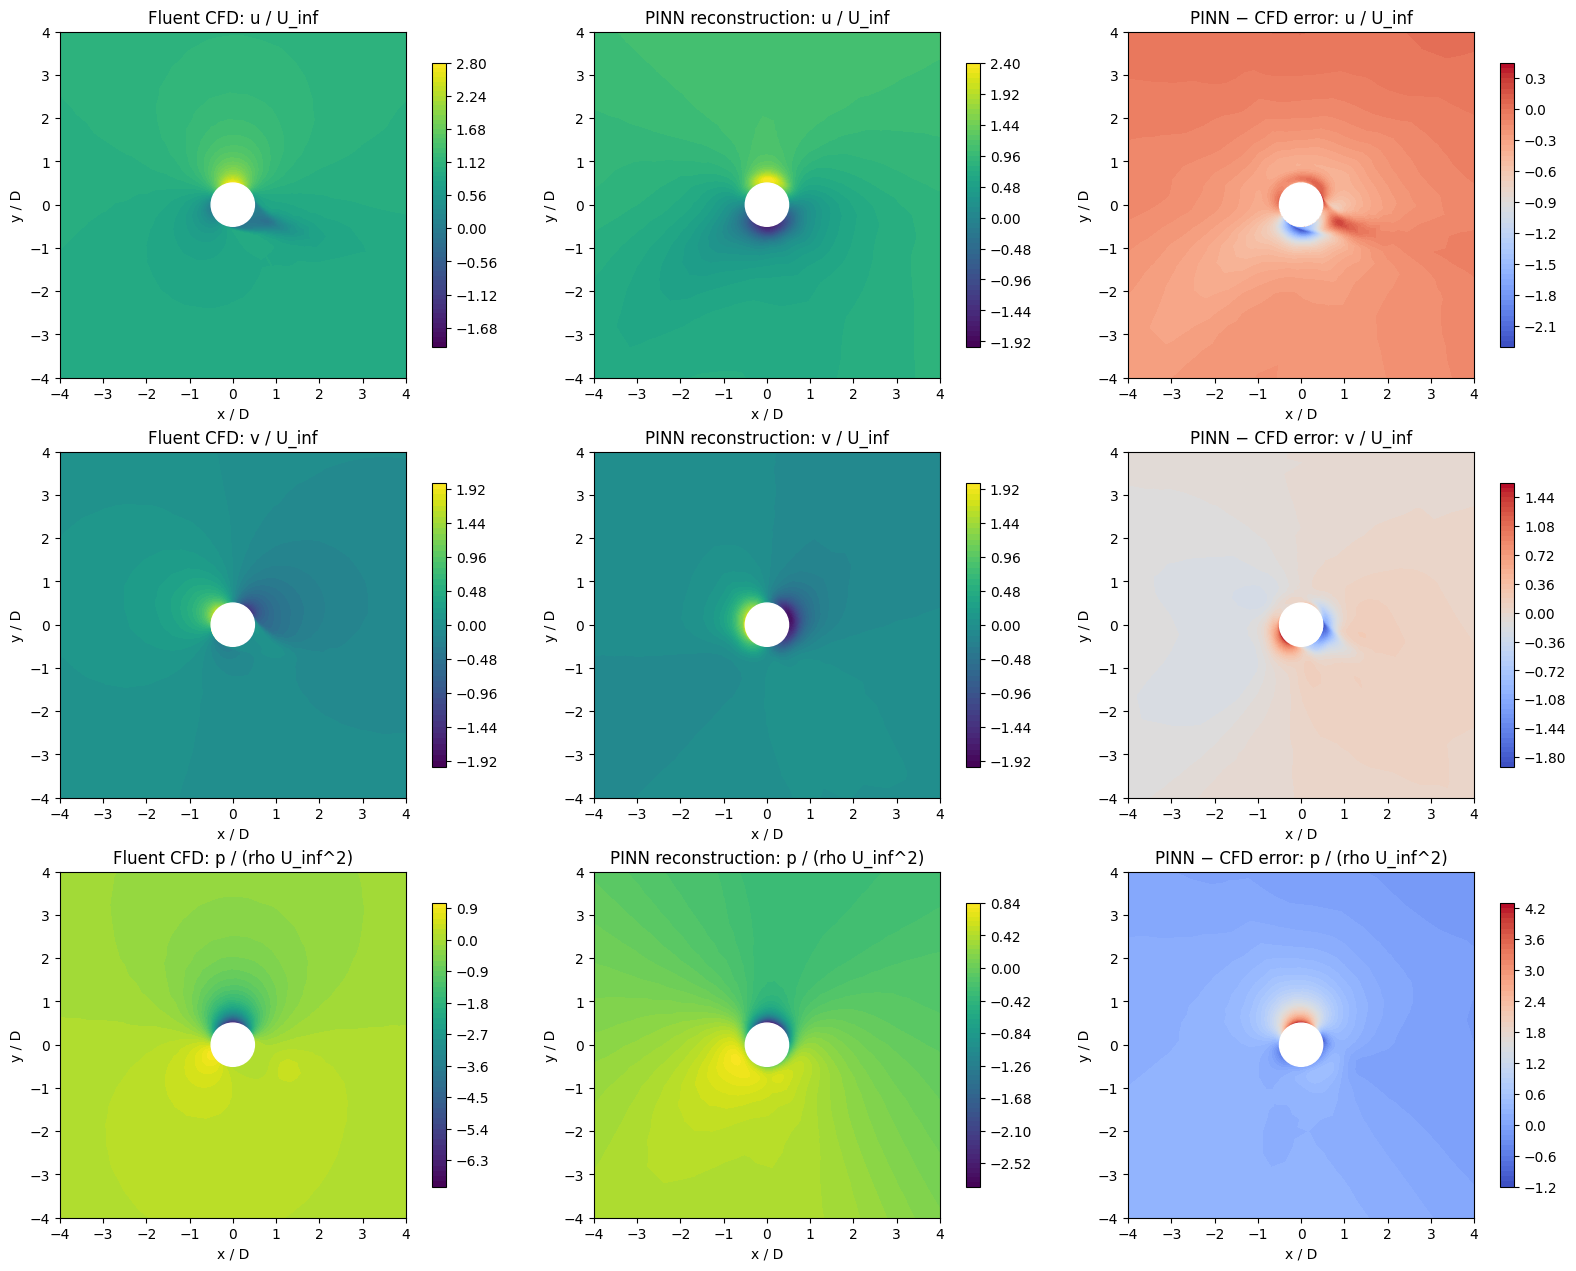

Velocity-vector error: MAE=0.45935, RMSE=0.73019 (nondimensional)
Interpretation: inspect the signed-error panels and the scalar metrics together; large errors near the cylinder can dominate pointwise statistics.


In [13]:
# Select the CFD CSV. In Colab, upload u_p_CFD_new.csv if it is not already present.
import os
CFD_CSV_PATH = "/content/u_p_CFD_new.csv"
if not os.path.exists(CFD_CSV_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_candidates = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_candidates:
            raise FileNotFoundError("No CSV uploaded. Please upload u_p_CFD_new.csv.")
        CFD_CSV_PATH = csv_candidates[0]
    except ImportError:
        # For local/Jupyter execution, upload or set CFD_CSV_PATH manually.
        raise FileNotFoundError(
            "Set CFD_CSV_PATH to the location of u_p_CFD_new.csv before running this cell."
        )

cfd = pd.read_csv(CFD_CSV_PATH)
required = {"x-coordinate", "y-coordinate", "x-velocity", "y-velocity"}
missing = required - set(cfd.columns)
if missing:
    raise ValueError(f"CFD CSV is missing required columns: {sorted(missing)}")

# Coordinates are already nondimensionalized by D (domain spans approximately -25 to 25).
x_cfd = cfd["x-coordinate"].to_numpy(dtype=np.float32)
y_cfd = cfd["y-coordinate"].to_numpy(dtype=np.float32)
u_cfd = cfd["x-velocity"].to_numpy(dtype=np.float32) / U_INF_PHYS
v_cfd = cfd["y-velocity"].to_numpy(dtype=np.float32) / U_INF_PHYS

# PINN pressure p is nondimensionalized by rho*U_inf^2.
if "expr:P_scaled" in cfd.columns:
    p_cfd = cfd["expr:P_scaled"].to_numpy(dtype=np.float32)
    pressure_source = "expr:P_scaled from CSV"
elif "pressure" in cfd.columns:
    # Requires pressure in Pa and rho=1.225 kg/m^3; adjust RHO_PHYS if needed.
    RHO_PHYS = 1.225
    p_cfd = cfd["pressure"].to_numpy(dtype=np.float32) / (RHO_PHYS * U_INF_PHYS**2)
    pressure_source = "pressure / (rho*U_inf^2), assuming rho=1.225 kg/m^3"
else:
    p_cfd = None
    pressure_source = "not available"

# Batched inference avoids GPU/CPU memory spikes for larger CFD meshes.
model.eval()
xy_np = np.column_stack([x_cfd, y_cfd]).astype(np.float32)
pred_chunks = []
with torch.no_grad():
    for start in range(0, len(xy_np), 2048):
        xy_batch = torch.tensor(xy_np[start:start+2048], dtype=torch.float32, device=DEVICE)
        outputs = model(xy_batch)
        # Model returns (u, v, p, k, omega, logk, logomega), each shaped [N, 1].
        pred_chunks.append(torch.cat(outputs[:3], dim=1).detach().cpu().numpy())
pred = np.concatenate(pred_chunks, axis=0)

u_pinn, v_pinn, p_pinn = pred[:, 0], pred[:, 1], pred[:, 2]

def error_metrics(reference, prediction):
    err = prediction - reference
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(np.mean(err**2)))
    scale = float(np.max(reference) - np.min(reference))
    nrmse = rmse / scale if scale > 1e-12 else np.nan
    return {"MAE": mae, "RMSE": rmse, "NRMSE_range": nrmse}

comparison = {
    "u / U_inf": error_metrics(u_cfd, u_pinn),
    "v / U_inf": error_metrics(v_cfd, v_pinn),
}
if p_cfd is not None:
    comparison["p / (rho U_inf^2)"] = error_metrics(p_cfd, p_pinn)

print(f"Compared {len(cfd):,} CFD points; pressure reference: {pressure_source}")
display(pd.DataFrame(comparison).T)

# Plot CFD, PINN reconstruction, and signed error on the same CFD coordinates.
import matplotlib.tri as mtri
tri = mtri.Triangulation(x_cfd, y_cfd)
triangles = tri.triangles
xc_tri = x_cfd[triangles].mean(axis=1)
yc_tri = y_cfd[triangles].mean(axis=1)
tri.set_mask(np.sqrt(xc_tri**2 + yc_tri**2) < R_IN)

fields = [
    ("u / U_inf", u_cfd, u_pinn, "u"),
    ("v / U_inf", v_cfd, v_pinn, "v"),
]
if p_cfd is not None:
    fields.append(("p / (rho U_inf^2)", p_cfd, p_pinn, "p"))

fig, axes = plt.subplots(len(fields), 3, figsize=(16, 4.2*len(fields)), constrained_layout=True)
if len(fields) == 1:
    axes = np.array([axes])
for row, (label, ref, recon, symbol) in enumerate(fields):
    err = recon - ref
    panels = [
        (ref, f"Fluent CFD: {label}", None),
        (recon, f"PINN reconstruction: {label}", None),
        (err, f"PINN − CFD error: {label}", "coolwarm"),
    ]
    for col, (values, title, cmap) in enumerate(panels):
        ax = axes[row, col]
        im = ax.tricontourf(tri, values, levels=60, cmap=cmap)
        ax.add_patch(plt.Circle((0, 0), R_IN, color="white", zorder=5))
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlim(-4, 4)
        ax.set_ylim(-4, 4)
        ax.set_xlabel("x / D")
        ax.set_ylabel("y / D")
        ax.set_title(title)
        fig.colorbar(im, ax=ax, shrink=0.82)
plt.show()

# Velocity-vector error summary (componentwise, nondimensional).
vel_err = np.sqrt((u_pinn-u_cfd)**2 + (v_pinn-v_cfd)**2)
vel_ref_mag = np.sqrt(u_cfd**2 + v_cfd**2)
print(f"Velocity-vector error: MAE={np.mean(vel_err):.5g}, "
      f"RMSE={np.sqrt(np.mean(vel_err**2)):.5g} (nondimensional)")
print("Interpretation: inspect the signed-error panels and the scalar metrics together; "
      "large errors near the cylinder can dominate pointwise statistics.")


## 8. Save outputs

The checkpoint and surface table can be downloaded from the Colab file browser. Save the run configuration and loss history along with any results you intend to report.

In [12]:
OUT_DIR = "/content/flettner_pinn_outputs" if os.path.isdir("/content") else "flettner_pinn_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
torch.save({"model_state_dict":model.state_dict(), "Re":RE, "alpha":ALPHA,
            "R_in":R_IN, "R_out":R_OUT, "run_mode":RUN_MODE,
            "omega_wall_target":OMEGA_WALL, "omega_wall_raw":OMEGA_WALL_RAW},
           os.path.join(OUT_DIR,"flettner_pinn_checkpoint.pt"))
surface_df.to_csv(os.path.join(OUT_DIR,"flettner_pinn_surface.csv"),index=False)
hist_df.to_csv(os.path.join(OUT_DIR,"flettner_pinn_loss_history.csv"),index=False)
print("Saved files in:", OUT_DIR)
print(os.listdir(OUT_DIR))

Saved files in: /content/flettner_pinn_outputs
['flettner_pinn_loss_history.csv', 'flettner_pinn_surface.csv', 'flettner_pinn_checkpoint.pt']


## 9. Before using results in a paper

- Run the full 6,000-epoch / 20,000-collocation-point configuration and repeat with at least 3 random seeds.
- Check the continuity, momentum, and SST residuals independently, not only the weighted total loss.
- Verify wall traction integration against an independent numerical quadrature and a manufactured/test solution.
- Compare the integrated pressure drag from $C_p(\theta)$ with the pressure component from the PINN and Fluent force reports.
- The uploaded manuscript reports a large discrepancy between its steady 2D Fluent drag ($C_D=0.22$) and the experiment ($C_D=1.745$). This notebook does not force the PINN toward experimental $C_D$; if it predicts the right drag, test whether that result is robust to seeds, collocation density, loss weights, and withheld $C_p$ observations.
- This is a steady 2D model. It cannot represent finite-span/end-plate effects or unsteady wake dynamics.